In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_theme(style='whitegrid')

# 1. Load Data

In [29]:
df = pd.read_csv('../../data/raw/HI-Small_Trans.csv')
df.head()

,Timestamp,From Bank,Account,To Bank,Account.1,Amount Received,Receiving Currency,Amount Paid,Payment Currency,Payment Format,Is Laundering
0,2022/09/01 00:20,10,8000EBD30,10,8000EBD30,3697.34,US Dollar,3697.34,US Dollar,Reinvestment,0
1,2022/09/01 00:20,3208,8000F4580,1,8000F5340,0.01,US Dollar,0.01,US Dollar,Cheque,0
2,2022/09/01 00:00,3209,8000F4670,3209,8000F4670,14675.57,US Dollar,14675.57,US Dollar,Reinvestment,0
3,2022/09/01 00:02,12,8000F5030,12,8000F5030,2806.97,US Dollar,2806.97,US Dollar,Reinvestment,0
4,2022/09/01 00:06,10,8000F5200,10,8000F5200,36682.97,US Dollar,36682.97,US Dollar,Reinvestment,0


# 2. Dataset Overview

## 2.1 remove the noise

In [30]:
df['Timestamp'] = pd.to_datetime(df['Timestamp'])

# threshold: drop days with fewer than 1000 total transactions
daily_counts = df.groupby(df['Timestamp'].dt.date).size()
valid_days = daily_counts[daily_counts >= 1000].index

df = df[df['Timestamp'].dt.date.isin(valid_days)]

summary = df.groupby(df['Timestamp'].dt.date)['Is Laundering'].agg(
    total_transactions='count',
    laundering_count='sum'
)
summary['laundering_rate_%'] = (summary['laundering_count'] / summary['total_transactions'] * 100).round(2)

print(summary)

            total_transactions  laundering_count  laundering_rate_%
Timestamp                                                          
2022-09-01             1114921               322               0.03
2022-09-02              754449               408               0.05
2022-09-03              207382               391               0.19
2022-09-04              207430               407               0.20
2022-09-05              482650               471               0.10
2022-09-06              482089               531               0.11
2022-09-07              482751               497               0.10
2022-09-08              482773               539               0.11
2022-09-09              654467               514               0.08
2022-09-10              208325               442               0.21


In [82]:
df = df[df['Amount Paid']>=0.01]

## 2.2 describe data


In [83]:
print(df.shape)
df.info()
df.describe()

(5043210, 15)
<class 'pandas.DataFrame'>
Index: 5043210 entries, 0 to 5078344
Data columns (total 15 columns):
 #   Column               Dtype         
---  ------               -----         
 0   Timestamp            datetime64[us]
 1   From Bank            str           
 2   Account              str           
 3   To Bank              str           
 4   Account.1            str           
 5   Amount Received      float64       
 6   Receiving Currency   str           
 7   Amount Paid          float64       
 8   Payment Currency     str           
 9   Payment Format       str           
 10  Is Laundering        int64         
 11  Sender_ID            str           
 12  Receiver_ID          str           
 13  amount_paid_usd      float64       
 14  amount_received_usd  float64       
dtypes: datetime64[us](1), float64(4), int64(1), str(9)
memory usage: 615.6 MB


,Timestamp,Amount Received,Amount Paid,Is Laundering,amount_paid_usd,amount_received_usd
count,5043210,5.043210e+06,5.043210e+06,5.043210e+06,5.043210e+06,5.043210e+06
mean,2022-09-05 07:15:34.148832,6.029730e+06,4.540032e+06,8.958580e-04,4.070747e+05,4.156792e+05
min,2022-09-01 00:00:00,1.000000e-06,1.000000e-02,0.000000e+00,6.900000e-05,1.000000e-06
25%,2022-09-02 04:34:00,1.910900e+02,1.922100e+02,0.000000e+00,1.383600e+02,1.383723e+02
50%,2022-09-05 12:17:00,1.446720e+03,1.450470e+03,0.000000e+00,8.358284e+02,8.363916e+02
75%,2022-09-08 03:13:00,1.255754e+04,1.251277e+04,0.000000e+00,5.230190e+03,5.236300e+03
max,2022-09-10 23:59:00,1.046302e+12,1.046302e+12,1.000000e+00,1.499632e+11,1.499632e+11
std,NaN,1.040789e+09,8.727971e+08,2.991748e-02,7.066463e+07,7.089821e+07


## 2.3 Missing Values and duplicated rows

In [84]:
df.isnull().sum()

Timestamp              0
From Bank              0
Account                0
To Bank                0
Account.1              0
Amount Received        0
Receiving Currency     0
Amount Paid            0
Payment Currency       0
Payment Format         0
Is Laundering          0
Sender_ID              0
Receiver_ID            0
amount_paid_usd        0
amount_received_usd    0
dtype: int64

In [85]:

print(df.duplicated().sum())
df.drop_duplicates(keep='first',inplace=True)
print(df.duplicated().sum())


0
0


## 2.4 class balance

In [86]:
df["Is Laundering"].value_counts()

Is Laundering
0    5038692
1       4518
Name: count, dtype: int64

In [87]:
df["Is Laundering"].value_counts(normalize=True)*100

Is Laundering
0    99.910414
1     0.089586
Name: proportion, dtype: float64

## 2.5 sanity check

In [88]:
print(df[['Amount Paid', 'Amount Received']].describe()) 
print("Negative Amount Paid:", (df['Amount Paid'] < 0).sum())
print("Zero Amount Paid:", (df['Amount Paid'] == 0).sum()) 
print("Negative Amount Received:", (df['Amount Received'] < 0).sum())
print("Zero Amount Received:", (df['Amount Received'] == 0).sum())

        Amount Paid  Amount Received
count  5.043210e+06     5.043210e+06
mean   4.540032e+06     6.029730e+06
std    8.727971e+08     1.040789e+09
min    1.000000e-02     1.000000e-06
25%    1.922100e+02     1.910900e+02
50%    1.450470e+03     1.446720e+03
75%    1.251277e+04     1.255754e+04
max    1.046302e+12     1.046302e+12
Negative Amount Paid: 0
Zero Amount Paid: 0
Negative Amount Received: 0
Zero Amount Received: 0


# 3. fix data types

In [89]:
df['Timestamp'] = pd.to_datetime(df['Timestamp']) 
df['From Bank'] = df['From Bank'].astype(str) 
df['To Bank'] = df['To Bank'].astype(str)  
df.dtypes

Timestamp              datetime64[us]
From Bank                         str
Account                           str
To Bank                           str
Account.1                         str
Amount Received               float64
Receiving Currency                str
Amount Paid                   float64
Payment Currency                  str
Payment Format                    str
Is Laundering                   int64
Sender_ID                         str
Receiver_ID                       str
amount_paid_usd               float64
amount_received_usd           float64
dtype: object

## 3.1 combine ID's

In [90]:
df['Sender_ID'] = df['Account'] + "_" + df['From Bank'] 
df['Receiver_ID'] = df['Account.1'] + "_" + df['To Bank']  
df[['Account', 'From Bank', 'Sender_ID']].head()

,Account,From Bank,Sender_ID
0,8000EBD30,10,8000EBD30_10
1,8000F4580,3208,8000F4580_3208
2,8000F4670,3209,8000F4670_3209
3,8000F5030,12,8000F5030_12
4,8000F5200,10,8000F5200_10


In [91]:
print("Unique Account (raw) values:", df['Account'].nunique())
print("Unique Sender_ID (combined) values:", df['Sender_ID'].nunique())

Unique Account (raw) values: 495492
Unique Sender_ID (combined) values: 495496


# 4. Oulier detection

### using "Amount Paid"

In [92]:
for fmt in df['Payment Format'].unique():
    subset_df = df[df['Payment Format'] == fmt]
    subset = subset_df['Amount Paid']
    log_subset = np.log1p(subset)
 
    Q1, Q3 = log_subset.quantile(0.25), log_subset.quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.1 * IQR, Q3 + 1.1 * IQR
 
    is_outlier = (log_subset < lower) | (log_subset > upper)
    outlier_pct = is_outlier.mean() * 100
 
    laundering_in_outliers = subset_df[is_outlier]['Is Laundering'].mean() * 100
    laundering_overall_fmt = subset_df['Is Laundering'].mean() * 100  # NEW
 
    print(f"{fmt}: {outlier_pct:.1f}% outliers | "
          f"Laundering in outliers: {laundering_in_outliers:.4f}% | "
          f"Laundering overall (this format): {laundering_overall_fmt:.4f}%")

Reinvestment: 0.2% outliers | Laundering in outliers: 0.0000% | Laundering overall (this format): 0.0000%
Cheque: 5.1% outliers | Laundering in outliers: 0.0146% | Laundering overall (this format): 0.0174%
Credit Card: 2.9% outliers | Laundering in outliers: 0.0104% | Laundering overall (this format): 0.0156%
ACH: 5.3% outliers | Laundering in outliers: 0.3681% | Laundering overall (this format): 0.6384%
Cash: 3.4% outliers | Laundering in outliers: 0.0182% | Laundering overall (this format): 0.0220%
Wire: 2.5% outliers | Laundering in outliers: 0.0000% | Laundering overall (this format): 0.0000%
Bitcoin: 15.1% outliers | Laundering in outliers: 0.0177% | Laundering overall (this format): 0.0464%


# 5.Feature analysis

## 5.1 Feature vs. loundering rate

In [93]:
categorical_cols = ['Payment Format', 'Receiving Currency', 'Payment Currency', 'From Bank', 'To Bank']
 
for col in categorical_cols:
    print(f"\n=== Laundering rate by {col} ===")
    result = df.groupby(col)['Is Laundering'].agg(['count', 'sum', 'mean'])
    result['mean'] = result['mean'] * 100
    result.columns = ['Total_Transactions', 'Laundering_Count', 'Laundering_Rate_%']
    print(result.sort_values('Laundering_Rate_%', ascending=False).head(10))


=== Laundering rate by Payment Format ===
                Total_Transactions  Laundering_Count  Laundering_Rate_%
Payment Format                                                         
ACH                         599656              3828           0.638366
Bitcoin                     112113                52           0.046382
Cash                        490891               108           0.022001
Cheque                     1864331               324           0.017379
Credit Card                1323324               206           0.015567
Reinvestment                481056                 0           0.000000
Wire                        171839                 0           0.000000

=== Laundering rate by Receiving Currency ===
                    Total_Transactions  Laundering_Count  Laundering_Rate_%
Receiving Currency                                                         
Saudi Riyal                      89890               302           0.335966
Euro                           117

In [94]:
df.groupby('Is Laundering')['Amount Paid'].describe()

,count,mean,std,min,25%,50%,75%,max
Is Laundering,,,,,,,,
0,5038692.0,4.507297e+06,8.718135e+08,0.010000,191.9300,1447.56,12497.460,1.046302e+12
1,4518.0,4.104722e+07,1.635467e+09,0.015667,2413.7275,7729.53,18200.725,8.485314e+10


# 6. visualizations

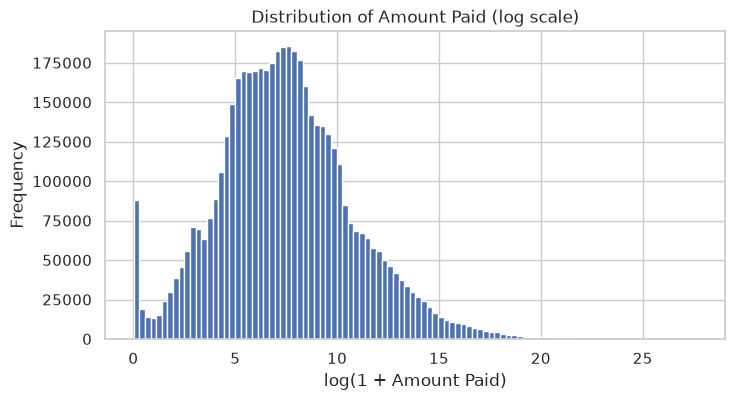

In [95]:
plt.figure(figsize=(8,4)) 
plt.hist(np.log1p(df['Amount Paid']), bins=100) 
plt.title("Distribution of Amount Paid (log scale)") 
plt.xlabel("log(1 + Amount Paid)") 
plt.ylabel("Frequency") 
plt.savefig("../../figures/01_amount_histogram_log.png", dpi=150, bbox_inches='tight') 
plt.show()

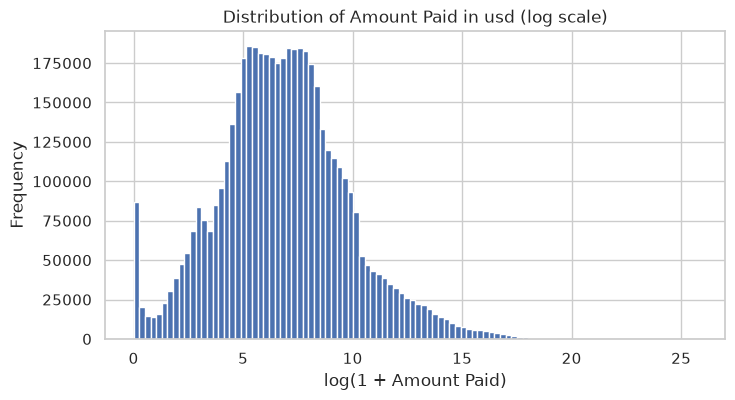

In [96]:
plt.figure(figsize=(8,4)) 
plt.hist(np.log1p(df['amount_paid_usd']), bins=100) 
plt.title("Distribution of Amount Paid in usd (log scale)") 
plt.xlabel("log(1 + Amount Paid)") 
plt.ylabel("Frequency") 
plt.savefig("../../figures/02_amount_usd_histogram_log.png", dpi=150, bbox_inches='tight') 
plt.show()

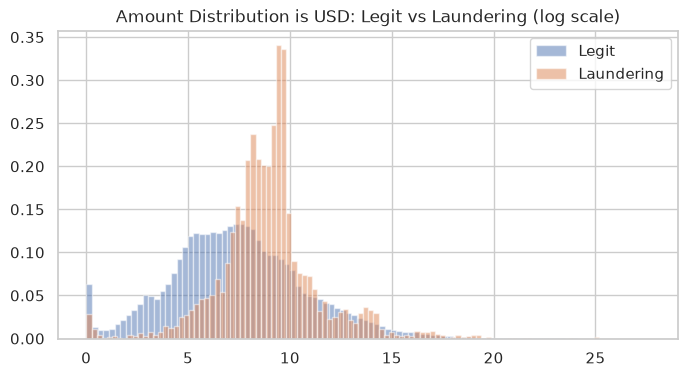

In [97]:
plt.figure(figsize=(8,4)) 
plt.hist(np.log1p(df[df['Is Laundering']==0]['Amount Paid']), bins=100, alpha=0.5, label='Legit', density=True) 
plt.hist(np.log1p(df[df['Is Laundering']==1]['Amount Paid']), bins=100, alpha=0.5, label='Laundering', density=True) 
plt.legend() 
plt.title("Amount Distribution is USD: Legit vs Laundering (log scale)") 
plt.savefig("../../figures/03_amount_dist_legit_vs_laundering.png", dpi=150, bbox_inches='tight') 
plt.show()

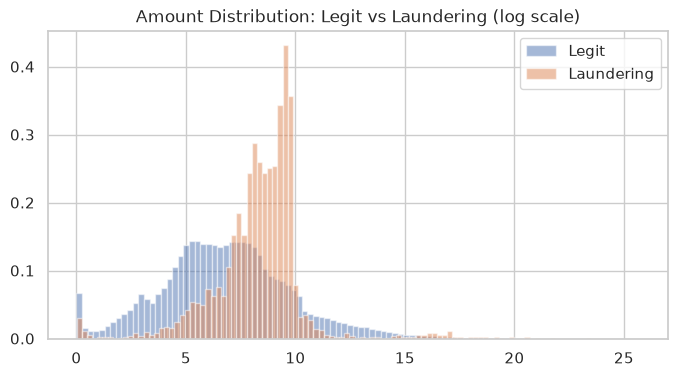

In [98]:
plt.figure(figsize=(8,4)) 
plt.hist(np.log1p(df[df['Is Laundering']==0]['amount_paid_usd']), bins=100, alpha=0.5, label='Legit', density=True) 
plt.hist(np.log1p(df[df['Is Laundering']==1]['amount_paid_usd']), bins=100, alpha=0.5, label='Laundering', density=True) 
plt.legend() 
plt.title("Amount Distribution: Legit vs Laundering (log scale)") 
plt.savefig("../../figures/04_amount_usd_dist_legit_vs_laundering.png", dpi=150, bbox_inches='tight') 
plt.show()

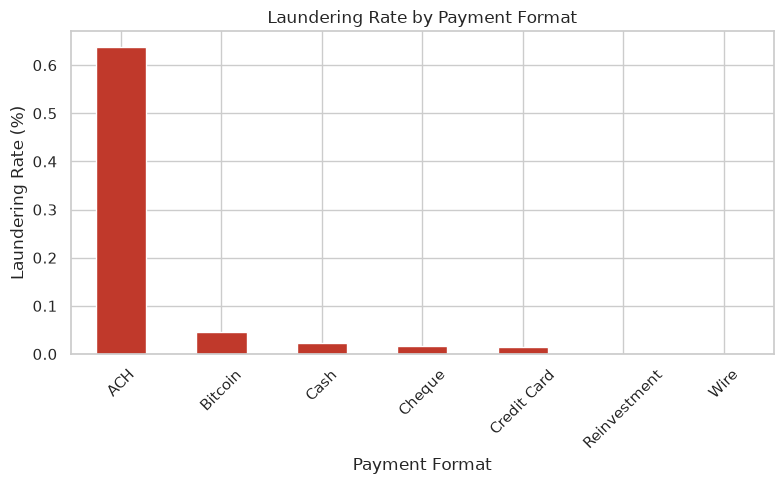

In [99]:
laundering_by_format = df.groupby('Payment Format')['Is Laundering'].mean().sort_values(ascending=False) * 100  
plt.figure(figsize=(8,5)) 
laundering_by_format.plot(kind='bar', color='#c0392b') 
plt.title("Laundering Rate by Payment Format") 
plt.ylabel("Laundering Rate (%)") 
plt.xlabel("Payment Format") 
plt.xticks(rotation=45) 
plt.tight_layout() 
plt.savefig("../../figures/03_laundering_rate_by_payment_format.png", dpi=150, bbox_inches='tight') 
plt.show()

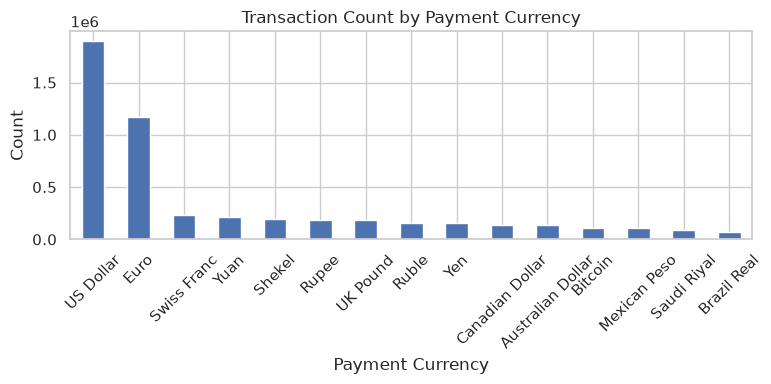

In [100]:
plt.figure(figsize=(8,4)) 
df['Payment Currency'].value_counts().plot(kind='bar') 
plt.title("Transaction Count by Payment Currency") 
plt.ylabel("Count") 
plt.xticks(rotation=45)
plt.tight_layout() 
plt.savefig("../../figures/04_currency_distribution.png", dpi=150, bbox_inches='tight') 
plt.show()

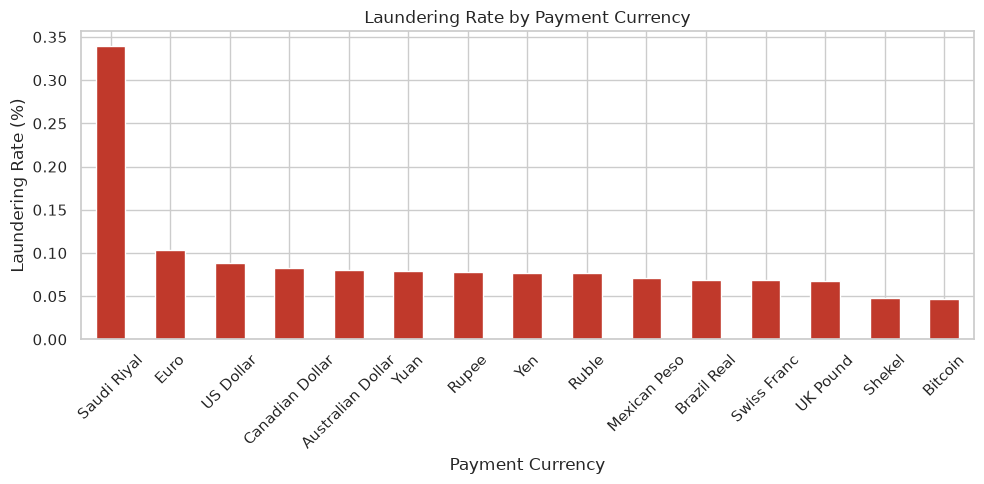

In [101]:
laundering_by_currency = df.groupby('Payment Currency')['Is Laundering'].mean().sort_values(ascending=False) * 100
 
plt.figure(figsize=(10,5))
laundering_by_currency.plot(kind='bar', color='#c0392b')
plt.title("Laundering Rate by Payment Currency")
plt.ylabel("Laundering Rate (%)")
plt.xlabel("Payment Currency")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("../../figures/05_laundering_rate_by_currency.png", dpi=150, bbox_inches='tight')
plt.show()

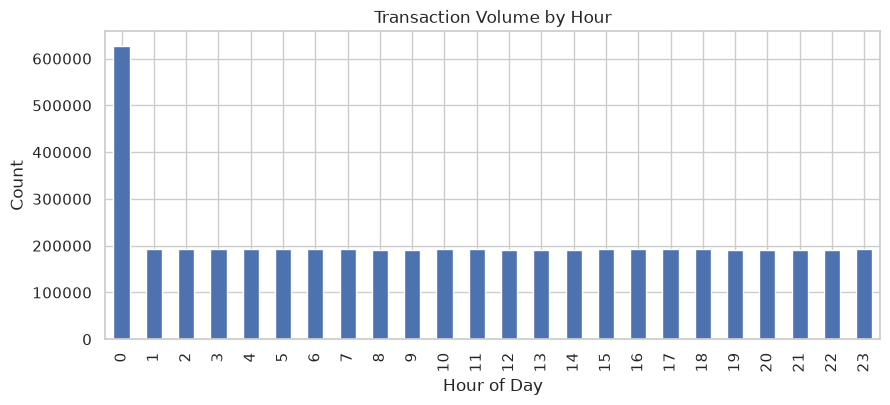

In [102]:
plt.figure(figsize=(10,4)) 
df['Timestamp'].dt.hour.value_counts().sort_index().plot(kind='bar') 
plt.title("Transaction Volume by Hour") 
plt.xlabel("Hour of Day") 
plt.ylabel("Count") 
plt.savefig("../../figures/06_transactions_by_hour.png", dpi=150, bbox_inches='tight') 
plt.show()

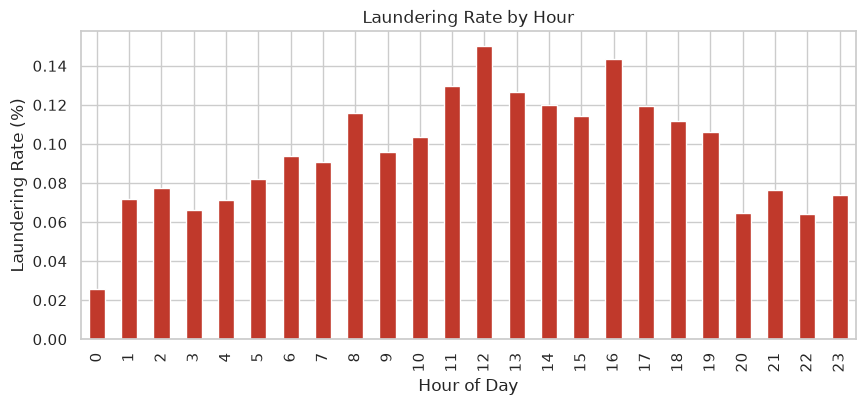

In [103]:
plt.figure(figsize=(10,4)) 
df.groupby(df['Timestamp'].dt.hour)['Is Laundering'].mean().mul(100).plot(kind='bar', color='#c0392b') 
plt.title("Laundering Rate by Hour") 
plt.xlabel("Hour of Day") 
plt.ylabel("Laundering Rate (%)") 
plt.savefig("../../figures/07_laundering_rate_by_hour.png", dpi=150, bbox_inches='tight') 
plt.show()

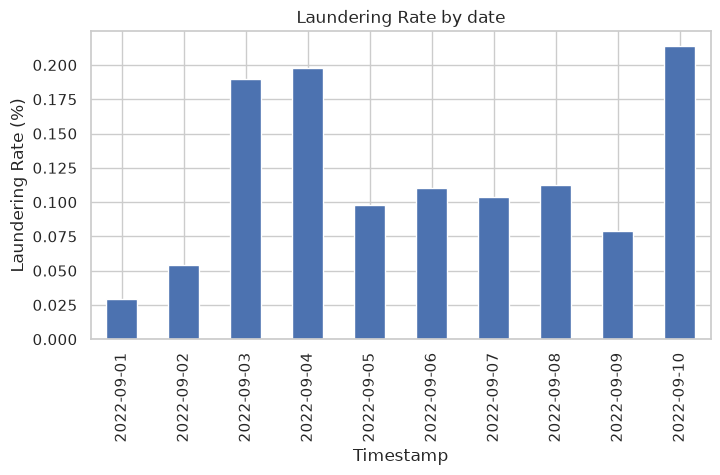

In [106]:
plt.figure(figsize=(8,4))
df.groupby(df['Timestamp'].dt.date)['Is Laundering'].mean().mul(100).plot(kind='bar')
plt.title("Laundering Rate by date")
plt.ylabel("Laundering Rate (%)")
plt.savefig("../../figures/08_laundering_rate_by_date.png", dpi=150, bbox_inches='tight')
plt.show()

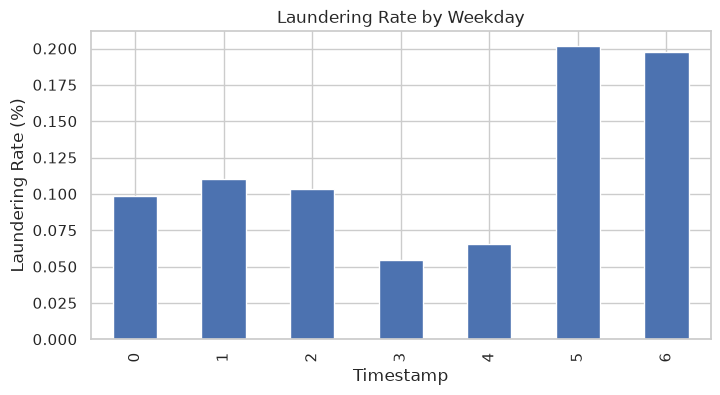

In [105]:
plt.figure(figsize=(8,4))
df.groupby(df['Timestamp'].dt.weekday)['Is Laundering'].mean().mul(100).plot(kind='bar')
plt.title("Laundering Rate by Weekday")
plt.ylabel("Laundering Rate (%)")
plt.savefig("../../figures/08_laundering_rate_by_weekday.png", dpi=150, bbox_inches='tight')
plt.show()